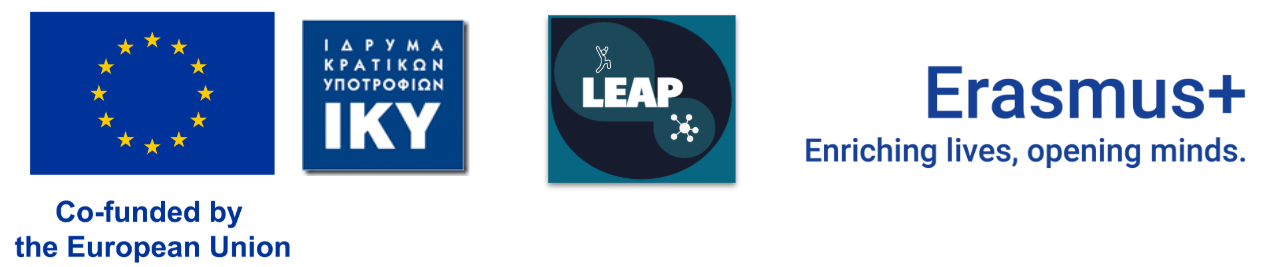

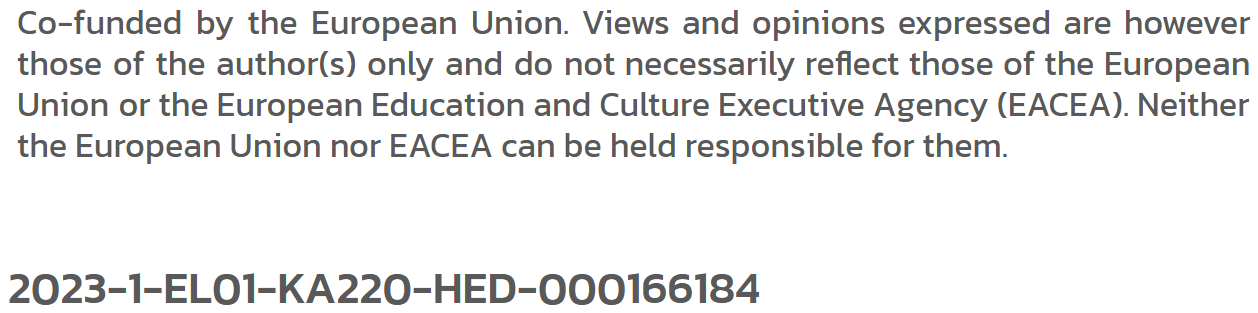

# Final Project, Option 1: Where does your CNN make its mistakes?

Software that reads handwritten numbers, such as postcodes on envelopes or account numbers on paper forms, must be judged not only on how often it is right but on where it goes wrong, because a confident misreading carries a real cost. In this project you build such a model and study the mistakes it makes.

In this project you build a convolutional neural network that recognises handwritten digits, then you study the mistakes it makes.

**Central question:** where does your CNN make its mistakes, and does one change to the model move them?

The data set is MNIST: 70,000 images of handwritten digits, each 28 by 28 pixels in greyscale, labelled 0 to 9. You download it yourself in the next cell.

This project draws on two earlier modules. In Module 5, we built and trained dense neural networks in Keras. In Module 6, we added convolutional layers, used Dropout and EarlyStopping to control overfitting, and read a confusion matrix to see which classes a model mixes up. Here you bring those skills together on a larger, more varied data set.

**How this notebook is organised.** The cells in Part A are already written for you. They handle the import, the download, and the reshaping that turns each flat row of 784 numbers back into a 28 by 28 image. From Part B onward, the cells are yours to complete. Each one carries comments describing what to do, along with a few hints, but not the finished code. Work through them in order.

Training on the full data set may take a few minutes per epoch on a laptop without a graphics card. This is expected.

## Part A. Setup and data

We start with the imports. This cell loads everything the notebook needs, so we run it once at the top.

In [17]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import keras
from keras import layers

### Loading the data

We download MNIST from OpenML. The call returns the images in `X` as 70,000 rows of 784 numbers, and the labels in `y` as text. We convert the labels to integers so the model can work with them. The download runs once and may take a moment.

In [18]:
X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True)
y = y.astype(int)

print("Images:", X.shape)
print("Labels:", y.shape, "| classes:", np.unique(y))

Images: (70000, 784)
Labels: (70000,) | classes: [0 1 2 3 4 5 6 7 8 9]


### Preparing the images

Each row of `X` is one image flattened into a line of 784 numbers. We reshape every row back into a 28 by 28 image with a single greyscale channel, and we scale the pixel values from the range 0 to 255 down to the range 0 to 1, which helps the network train. We then split the data into a training set and a test set, keeping the class balance with `stratify`, as we did in Module 3.

In [19]:
X = X.reshape(-1, 28, 28, 1).astype("float32") / 255.0

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training images:", X_train.shape)
print("Test images:    ", X_test.shape)

# If training is slow on your machine, you may work with a smaller sample
# while you get everything running, for example:
#   X_train, y_train = X_train[:10000], y_train[:10000]

Training images: (56000, 28, 28, 1)
Test images:     (14000, 28, 28, 1)


### A first look at the images

Before modelling, we look at a few training images with their labels, to confirm the data loaded correctly.

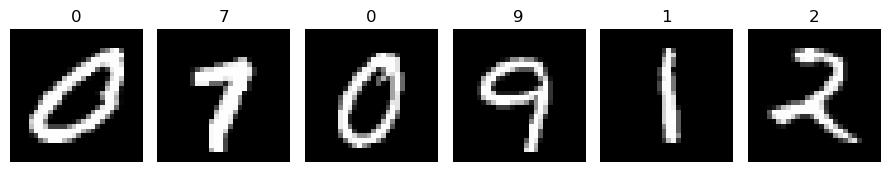

In [20]:
fig, axes = plt.subplots(1, 6, figsize=(9, 2))
for ax, image, label in zip(axes, X_train, y_train):
    ax.imshow(image.reshape(28, 28), cmap="gray")
    ax.set_title(str(label))
    ax.axis("off")
plt.tight_layout()
plt.show()

## Part B. Build and train your network

From here on, the cells are yours to complete.

First, build a convolutional neural network with the Keras Sequential API, the same style you used in Module 6. Recall the shape of one image: 28 by 28, with one channel.

In [ ]:
# Fix the random seed so that rerunning the notebook gives comparable results.
keras.utils.set_random_seed(42)

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3,3), activation="relu", padding="same"), # We use the padding as suggested on lesson 6.
    layers.MaxPooling2D((2, 2)),

    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax") # One unit for each digit from 0 to 9
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       401,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 402,442 (1.54 MB)

 Trainable params: 402,442 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

### Compile the model

Compiling sets the optimiser, the loss function, and the metric to watch during training.

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3), #Standard choice.
    loss="sparse_categorical_crossentropy", # This loss function is useful given that we have many categories, and the labels are integers, as it was explained during the lesson.
    metrics=["accuracy"], #Accuracy measures the proportion of correctly classified samples out of the total samples.
)

### Train the model

Train the network, watching how it performs on data it has not learnt from. `EarlyStopping` halts training once the validation loss stops improving, so you do not waste time or overfit.

In [ ]:
## We will split the training set into a training and validation set to tune our model.

X_train_final, X_validation, y_train_final, y_validation = train_test_split(
    X_train, y_train, test_size=0.1, stratify=y_train, random_state=42
)


early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,                 # wait 3 epochs without improvement before stopping
    restore_best_weights=True,  # keep the values from the best epoch
)

history = model.fit(
    X_train_final, y_train_final,
    validation_data=(X_validation, y_validation),
    epochs=15,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=2,
)

Epoch 1/15
394/394 - 4s - 10ms/step - accuracy: 0.9170 - loss: 0.2943 - val_accuracy: 0.9620 - val_loss: 0.1256
Epoch 2/15
394/394 - 3s - 8ms/step - accuracy: 0.9710 - loss: 0.0978 - val_accuracy: 0.9737 - val_loss: 0.0827
Epoch 3/15
394/394 - 3s - 8ms/step - accuracy: 0.9782 - loss: 0.0712 - val_accuracy: 0.9773 - val_loss: 0.0687
Epoch 4/15
394/394 - 3s - 8ms/step - accuracy: 0.9827 - loss: 0.0580 - val_accuracy: 0.9795 - val_loss: 0.0623
Epoch 5/15
394/394 - 3s - 8ms/step - accuracy: 0.9848 - loss: 0.0481 - val_accuracy: 0.9807 - val_loss: 0.0615
Epoch 6/15
394/394 - 3s - 8ms/step - accuracy: 0.9863 - loss: 0.0419 - val_accuracy: 0.9812 - val_loss: 0.0556
Epoch 7/15
394/394 - 3s - 7ms/step - accuracy: 0.9882 - loss: 0.0363 - val_accuracy: 0.9832 - val_loss: 0.0547
Epoch 8/15
394/394 - 3s - 8ms/step - accuracy: 0.9901 - loss: 0.0318 - val_accuracy: 0.9836 - val_loss: 0.0529
Epoch 9/15
394/394 - 3s - 8ms/step - accuracy: 0.9908 - loss: 0.0286 - val_accuracy: 0.9846 - val_loss: 0.0481


### Learning curves

Plot the training and validation loss across the epochs. A validation curve that flattens or turns upward while the training curve keeps falling is a sign of overfitting.

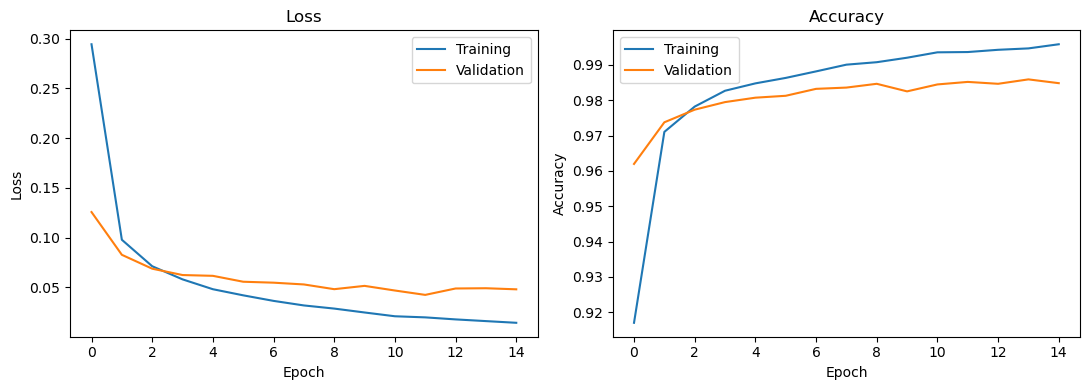

In [ ]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))

ax_loss.plot(history.history["loss"], label="Training")
ax_loss.plot(history.history["val_loss"], label="Validation")
ax_loss.set_xlabel("Epoch"); ax_loss.set_ylabel("Loss")
ax_loss.set_title("Loss"); ax_loss.legend()

ax_acc.plot(history.history["accuracy"], label="Training")
ax_acc.plot(history.history["val_accuracy"], label="Validation")
ax_acc.set_xlabel("Epoch"); ax_acc.set_ylabel("Accuracy")
ax_acc.set_title("Accuracy"); ax_acc.legend()

plt.tight_layout()
plt.show()


## Part C. Read the mistakes

Now measure how well the model does on the test set, the images it has never seen. This gives a reliable estimate of how it will perform on new images.

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test loss: {test_loss:.3f}")


y_pred_probabilities = model.predict(X_test, verbose=0)  # a score for each digit
y_pred = np.argmax(y_pred_probabilities, axis=1)         # the digit with the highest score

print(f"Predicted classes for the first 10 test images: {y_pred[:10]}")

Test accuracy: 0.987
Test loss: 0.043
Predicted classes for the first 10 test images: [7 3 1 1 2 5 9 8 8 1]


### The confusion matrix

The confusion matrix is where you answer the first half of the central question: where the mistakes are. Read it by rows. Each row is a true digit, each column is the digit the model predicted. The diagonal holds the correct predictions; every off-diagonal cell is a mistake, and its position tells you which digit was mistaken for which.

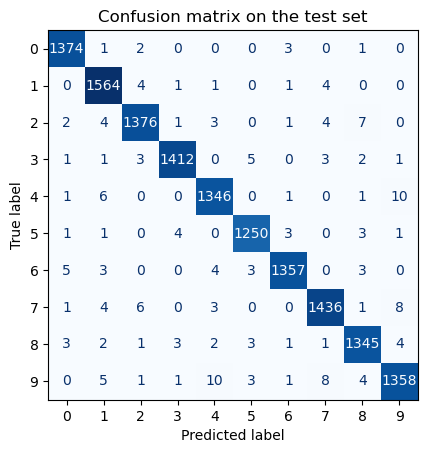

In [ ]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
disp.plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix on the test set")
plt.show()


### What did you find?

Look at the off-diagonal cells with the largest counts. Which pairs of digits does your model confuse most often? Some pairs are visually similar and are commonly mixed up.

**Write two or three sentences here** naming the two most common confusion pairs, recording the count for each one, and suggesting why those particular digits might be hard to tell apart. For example, if row 4 and column 9 contains 18, the model predicted 9 for 18 images that were actually 4.

**Answer**

The model seems to have problems classifying the numbers 9, 8 and 2. We found that it commonly confuses the number 9 with the number 4, so that 10 true "4" are classified as "9", and viceversa. Many people, when writing fast, might write a "closed" number 4, and if the calligraphy of the person is more on the rounded side, it will look like a 9. This implies that when looking at the feature map (basically a simplified shape), the network will observe a greater density of pixels around it, which might look similar to the density of pixels of the "circle" of a 9.

## Part D. One change

Now answer the second half of the central question: does one change to the model move the mistakes?

Choose **one** change from the two below. Do not make both at once, or you will not know which one caused any difference you see.

- **Option A: a deeper network.** Before the Flatten layer, add `Conv2D(64, (3, 3), activation="relu")` followed by `MaxPooling2D((2, 2))`. This lets the network learn more detailed patterns.
- **Option B: stronger regularisation.** Raise the Dropout rate from 0.3 to 0.5. This makes the network rely less on any single feature.

**Before you run anything, write down your prediction:** will your chosen change raise the test accuracy, and will it reduce the confusion between the pairs you found in Part C? Note it here.

Neural-network training contains some randomness. A very small difference in accuracy does not necessarily show that one model is genuinely better. Look at the size of the difference and at the specific mistakes, not only at which accuracy is larger.

**Answer**

I will choose option B, raising the dropout rate. A higher dropout should allow the model to learn from more robust features, given that less neurons will be communicating with each other during the training. Although it might not result in a higher accuracy (we already have an accuracy of 98.7%), we should have a higher confidence on the prediction itself, that is, the loss should be lower.

In [ ]:
# Use the same seed as before to make the comparison more reproducible.
keras.utils.set_random_seed(42)

model2 = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3,3), activation="relu", padding="same"), # We use the padding as suggested on lesson 6.
    layers.MaxPooling2D((2, 2)),

   ## Change

    layers.Dropout(0.5), #We have increased the dropout rate to 0.5.

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax") # One unit for each digit from 0 to 9
])

model2.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       401,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 402,442 (1.54 MB)

 Trainable params: 402,442 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3), #Standard choice.
    loss="sparse_categorical_crossentropy", # This loss function is useful given that we have many categories, and the labels are integers, as it was explained during the lesson.
    metrics=["accuracy"], #Accuracy measures the proportion of correctly classified samples out of the total samples.
)

history2 = model2.fit(
    X_train_final, y_train_final,
    validation_data=(X_validation, y_validation),
    epochs=15,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=2,
)

Epoch 1/15
394/394 - 4s - 9ms/step - accuracy: 0.9097 - loss: 0.3157 - val_accuracy: 0.9577 - val_loss: 0.1360
Epoch 2/15
394/394 - 3s - 8ms/step - accuracy: 0.9648 - loss: 0.1183 - val_accuracy: 0.9712 - val_loss: 0.0879
Epoch 3/15
394/394 - 3s - 7ms/step - accuracy: 0.9733 - loss: 0.0884 - val_accuracy: 0.9775 - val_loss: 0.0728
Epoch 4/15
394/394 - 3s - 7ms/step - accuracy: 0.9773 - loss: 0.0741 - val_accuracy: 0.9773 - val_loss: 0.0639
Epoch 5/15
394/394 - 3s - 7ms/step - accuracy: 0.9804 - loss: 0.0624 - val_accuracy: 0.9796 - val_loss: 0.0622
Epoch 6/15
394/394 - 3s - 7ms/step - accuracy: 0.9825 - loss: 0.0555 - val_accuracy: 0.9811 - val_loss: 0.0572
Epoch 7/15
394/394 - 3s - 7ms/step - accuracy: 0.9834 - loss: 0.0506 - val_accuracy: 0.9818 - val_loss: 0.0539
Epoch 8/15
394/394 - 3s - 7ms/step - accuracy: 0.9857 - loss: 0.0442 - val_accuracy: 0.9818 - val_loss: 0.0551
Epoch 9/15
394/394 - 3s - 7ms/step - accuracy: 0.9863 - loss: 0.0413 - val_accuracy: 0.9843 - val_loss: 0.0462
E

Test accuracy of model 2: 0.988 versus model 1: 0.987
Test loss of model 2: 0.041 versus model 1: 0.043


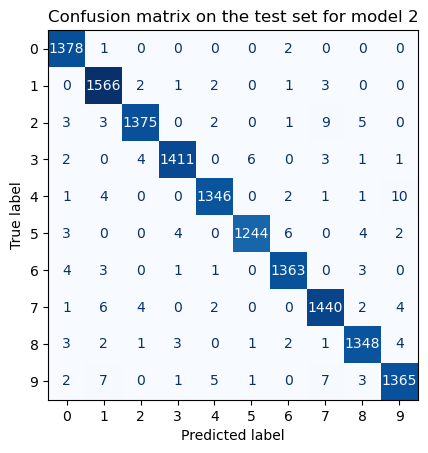

In [ ]:
test_loss2, test_accuracy2 = model2.evaluate(X_test, y_test, verbose=0)

print(f"Test accuracy of model 2: {test_accuracy2:.3f} versus model 1: {test_accuracy:.3f}")
print(f"Test loss of model 2: {test_loss2:.3f} versus model 1: {test_loss:.3f}")

y_pred2_probabilities = model2.predict(X_test, verbose=0)  # a score for each digit
y_pred2 = np.argmax(y_pred2_probabilities, axis=1)         # the digit with the highest score

cm2 = confusion_matrix(y_test, y_pred2)

disp2 = ConfusionMatrixDisplay(confusion_matrix=cm2, display_labels=range(10))
disp2.plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix on the test set for model 2")
plt.show()

### Ethical considerations

A digit reader does not perform equally well for everyone. Handwriting varies by age, country, and schooling, and a model trained mostly on one style may read another less reliably.
**Write two or three sentences here** on the risks of putting this model into a real reading pipeline. Consider whose handwriting might be under-represented in the training data, and what the consequence of a confident but wrong reading would be in the setting above.

**Answer**

The accuracy of a model depends a lot on the data with which it is trained. Given the clear shapes of the digits seen in the images above, it is possible that the dataset used here was written by adults, possibly with higher education and of the environment of the developers of scikit.

People with difficulties to write (for example, people with disabilities, kids in early schooling or those with little formal education) will probably be "problematic" for the model, as it probably won't be able to classify their handwritting with clarity, If it was used on a postal service, as suggested above, it would cause that a small proportion of the letters to be delivered to the wrong place, but this small proportion still might be a significant number of wrong deliveries on a big city.


## Wrapping up

Bring your findings together. **Write a short paragraph** that answers the central question directly:

- Where did your first model make most of its mistakes?
- Did your prediction in Part D turn out to be correct?
- For each of the two confusion pairs you identified, what was the count before and after the change?
- Did your one change move the mistakes, and is the difference large enough to be meaningful?

**What to hand in:** this completed notebook, with both confusion matrices visible in the output, and your written answers in the three markdown cells above (Part C, Part D, and this one).

**Answer**

Our original model had the most troubles telling apart the numbers 4 and 9, mainly bewteen each other, but also with a high error count between them and the number 8, so the adapted model set a highet dropout rate to increase the robustness of the predictions. As we suposed in part D, the accuracy of the model basically did not improve (an increment of 0.1% is almost neglible), but contrary with our prediction, the loss did not improve significatively either (it passed from 0.043 to 0.041), so we could say that our prediction was partially correct. With the second model, the number of true 4 classified as 9 remained the same (10 counts), but the number of true 9 classified as 4 halved, diminishing to 5 counts. This improvement, although important, is not really meaningful, so the model still would not be ideal to be implemented on a real life scenario. 